# Map and reduce with remote tasks

Two mapper tasks run in parallel and a reducer task combines their results. Ray passes the mapper ObjectRefs straight into the reducer, so the driver never waits in between.

**When to use it.** Any job that splits into independent pieces of work followed by one combining step: per-file parsing then a merge, per-shard statistics then a total.

The picture below is the graph drawn in Eugo's visual Ray builder, and the cell under *Generated code* is the Ray code the builder produced from it. The code is plain Ray: it runs without the builder.

[Back to the gallery](../README.md) · Tested with Ray 2.55.1

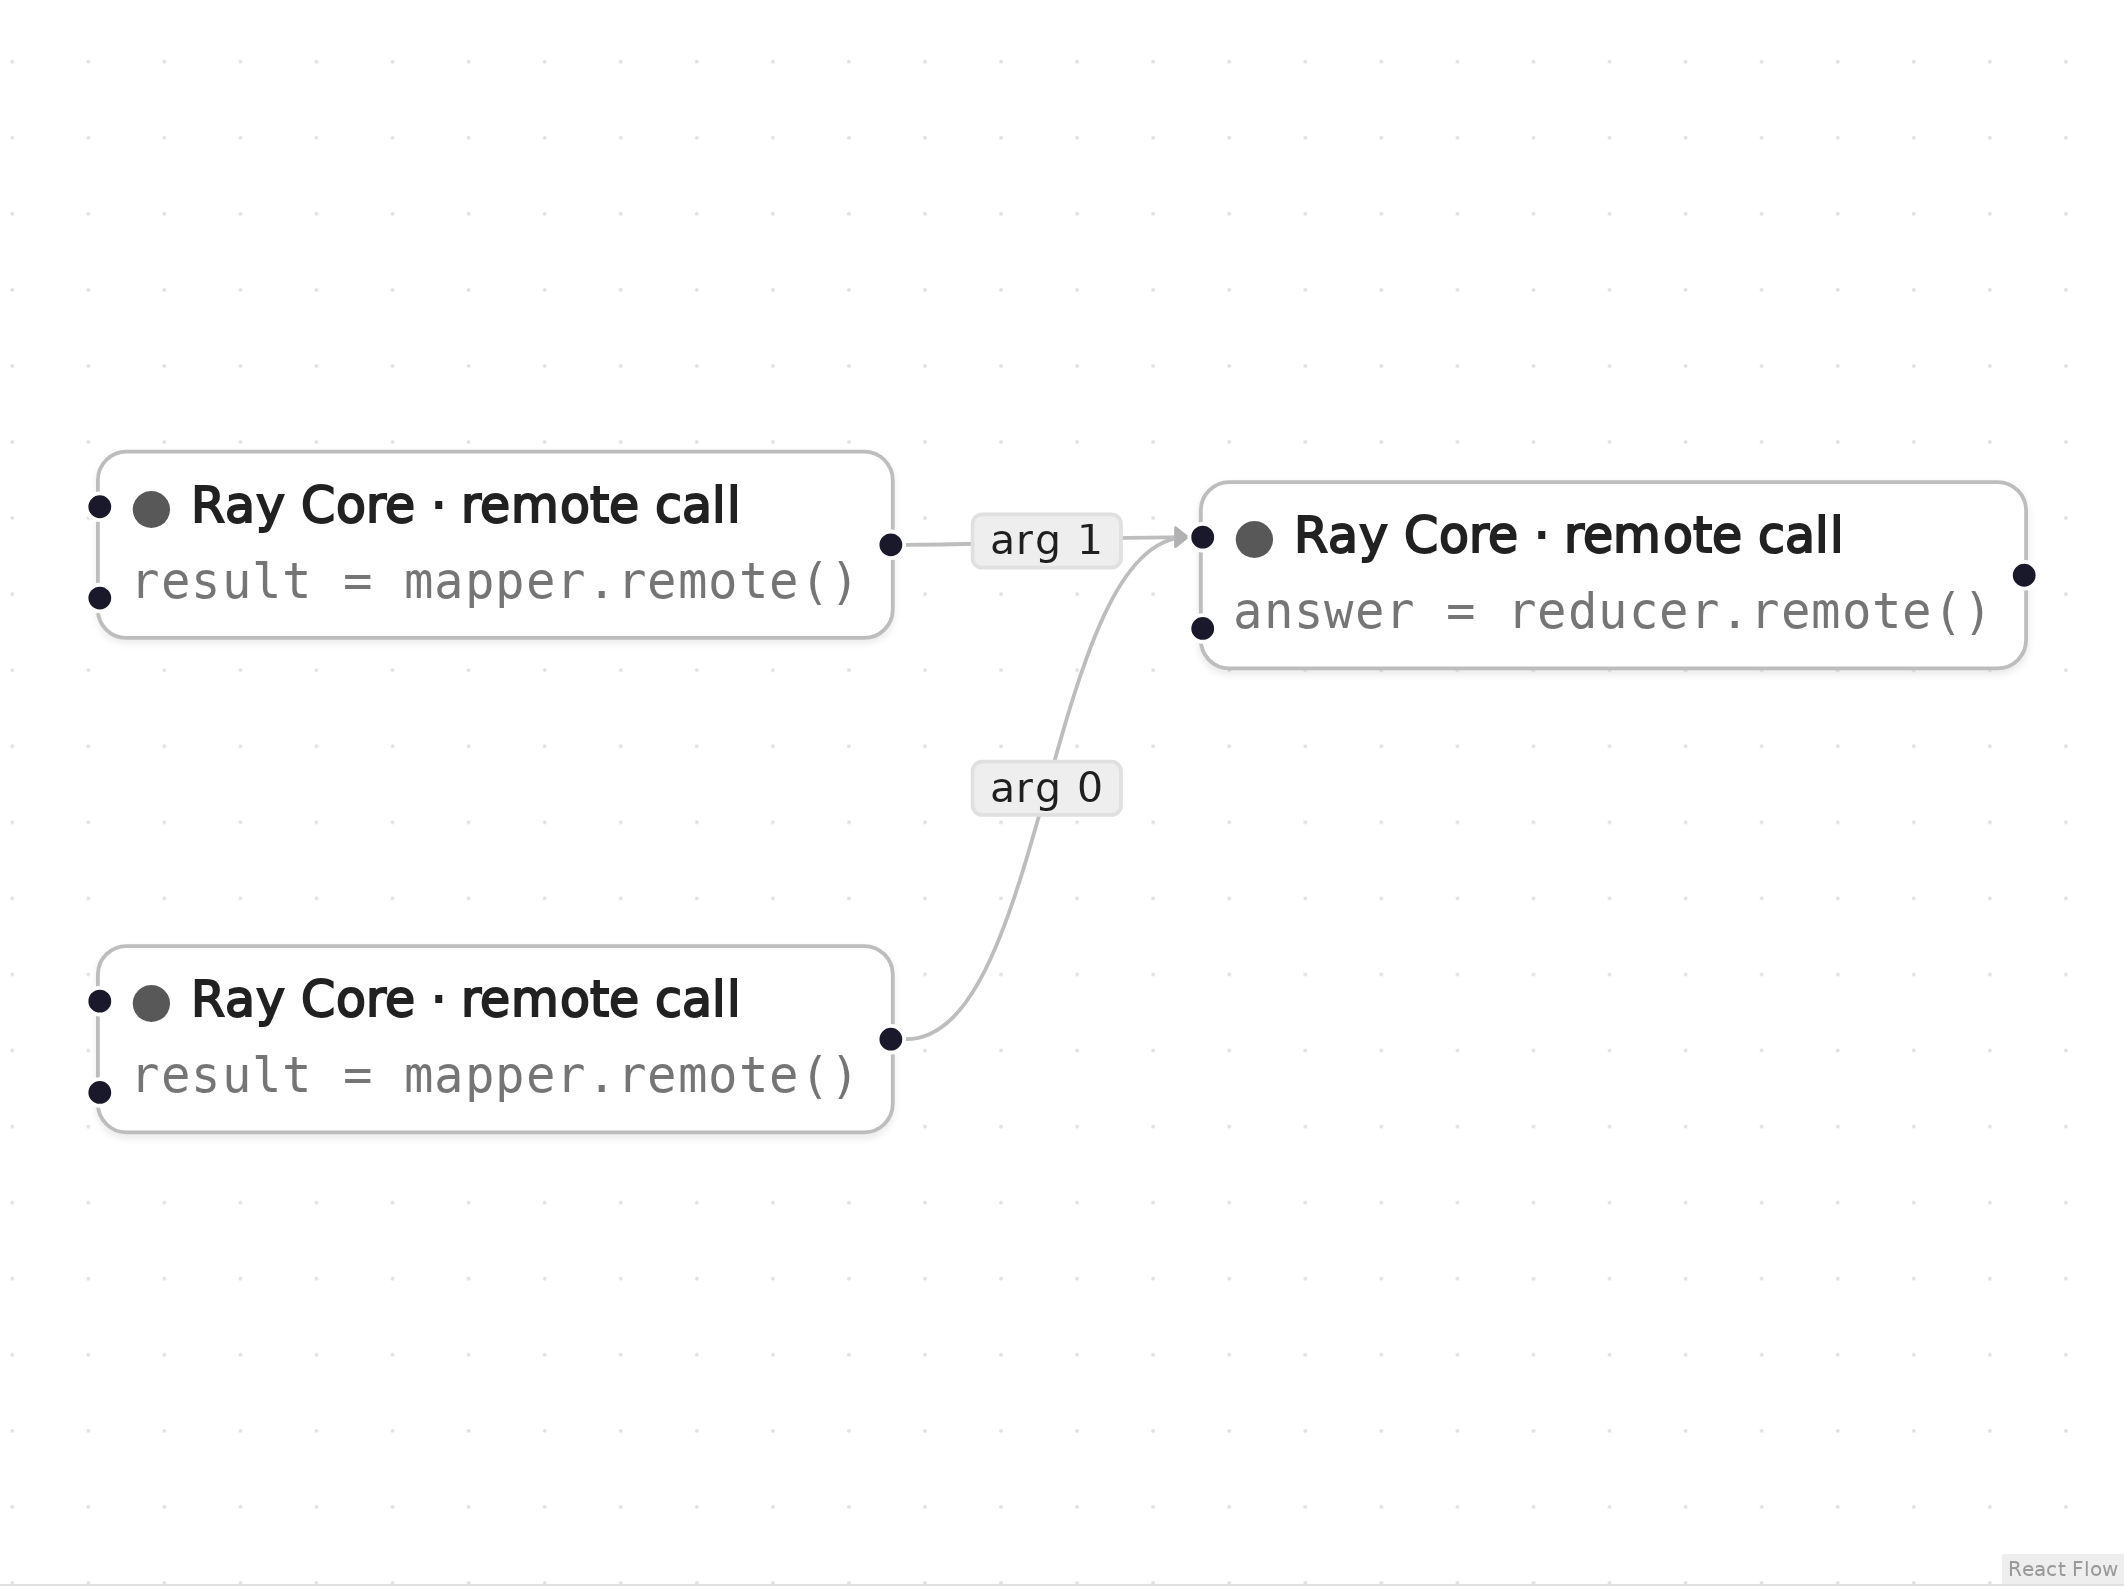

*The graph in Eugo's visual Ray builder.* Both mappers show `mapper.remote()`. The upper box is the second mapper (`n2`, `mapper(2)`), wired to *arg 1*; the lower box is the first mapper (`n1`, `mapper(1)`), wired to *arg 0*.

## Setup

Start a local Ray instance. The options keep the notebook quiet: no dashboard, and worker logs stay out of the notebook. Ray is capped at four CPUs so the example behaves the same on any machine. The generated code below only calls `ray.init()` when Ray is not running yet, so it reuses this instance.

In [1]:
import ray
ray.init(include_dashboard=False, log_to_driver=False, logging_level="ERROR", num_cpus=4)

RayContext(dashboard_url='', python_version='3.12.3', ray_version='2.55.1', ray_commit='237c2455ebb1ea15a32dd9e1fdeb2d617badc37f')

## User functions

The nodes in the graph call these ordinary Python functions and classes. In the builder you write them in a normal notebook cell, and the generated code refers to them by name.

In [2]:
def mapper(x):
    # Runs as a Ray task, one call per input.
    return x * 2


def reducer(*parts):
    # Ray resolves the mapper ObjectRefs before this runs, so parts are plain values.
    return sum(parts)

## Generated code

This is the cell the visual builder generated from the graph above.

In [3]:
# Generated with Eugo's visual Ray builder

import ray

if not ray.is_initialized():
    ray.init()

_n1 = ray.remote(mapper).remote(1)
_n2 = ray.remote(mapper).remote(2)
_n3 = ray.remote(reducer).remote(_n1, _n2)
answer = ray.get(_n3)

## Check the result

The cell below checks that the generated code did what the graph describes.

In [4]:
assert answer == 6, answer
print("answer =", answer)

answer = 6


## How the graph maps to the code

Each step names a node in the picture, the lines of the generated cell it produced, and what those lines do. The node id (for example `n1`) is also the suffix of the variable that holds the node's result.

**Setup** (lines 1, 3 and 5–6)

```python
# Generated with Eugo's visual Ray builder
...
import ray
...
if not ray.is_initialized():
    ray.init()
```

The first line marks the cell as generated. The builder then adds an import for every Ray API the graph uses and a guarded ray.init(), so re-running the cell reuses the running cluster.

**Remote task** (node `n1`, line 8)

```python
_n1 = ray.remote(mapper).remote(1)
```

The first mapper task. ray.remote(mapper) turns the plain function into a task and .remote(1) schedules it; _n1 is an ObjectRef, not the value.

**Remote task** (node `n2`, line 9)

```python
_n2 = ray.remote(mapper).remote(2)
```

The second mapper task runs in parallel with the first.

**Remote task** (node `n3`, lines 10–11)

```python
_n3 = ray.remote(reducer).remote(_n1, _n2)
answer = ray.get(_n3)
```

The reducer receives both ObjectRefs as positional arguments (the edge labels give the order). Ray waits for them before running it, and ray.get fetches the final value.

## Other ways the builder can emit this graph

The builder can emit the same graph in other forms. They are shown here as text and are not run by this notebook.

### The same graph as a lazy DAG with `bind()`

The builder can emit `.bind()` calls instead of `.remote()`. Nothing runs until `execute()` is called on the last node. This version was also run on Ray 2.55.1 with the same check.

```python
# Generated with Eugo's visual Ray builder

import ray

if not ray.is_initialized():
    ray.init()

_n1 = ray.remote(mapper).bind(1)
_n2 = ray.remote(mapper).bind(2)
_n3 = ray.remote(reducer).bind(_n1, _n2)
answer = ray.get(_n3.execute())
```

### One cell per node

The builder can also split the generated code into one notebook cell per node, so each step can be re-run on its own.

*Cell 1*

```python
# Generated with Eugo's visual Ray builder

import ray

if not ray.is_initialized():
    ray.init()
```

*Cell 2*

```python
_n1 = ray.remote(mapper).remote(1)
```

*Cell 3*

```python
_n2 = ray.remote(mapper).remote(2)
```

*Cell 4*

```python
_n3 = ray.remote(reducer).remote(_n1, _n2)
answer = ray.get(_n3)
```

### As a standalone script (`map_reduce.py`)

The builder can export the graph as a Python module: the user functions are copied in and the Ray calls go under `if __name__ == "__main__":`. It was run as a script on Ray 2.55.1.

```python
# Generated with Eugo's visual Ray builder

# Best-effort standalone export: cells defining referenced functions/classes
# were inlined. Transitive helpers from OTHER cells, referenced notebook VARIABLES
# (e.g. a Data source's `df`), and notebook magics (commented out) may need manual
# edits. Re-exporting overwrites this file.

import ray

def mapper(x):
    # Runs as a Ray task, one call per input.
    return x * 2


def reducer(*parts):
    # Ray resolves the mapper ObjectRefs before this runs, so parts are plain values.
    return sum(parts)

if __name__ == "__main__":
    ray.init()

    _n1 = ray.remote(mapper).remote(1)
    _n2 = ray.remote(mapper).remote(2)
    _n3 = ray.remote(reducer).remote(_n1, _n2)
    answer = ray.get(_n3)
    ray.shutdown()
```

### Submit the script as a Ray Job

The builder also writes a small shell script that submits the exported module with the Ray Jobs CLI. It needs a running Ray cluster whose dashboard (the Jobs API) is reachable at the address in the script, so it was not run here.

```bash
#!/usr/bin/env bash
set -euo pipefail

# Submit this Ray DAG to a cluster as a job — Ray Jobs CLI (`ray job submit`), verified on Ray 2.55.1.
# `--working-dir .` packages and ships THIS directory to the cluster (the file-upload mechanism),
# so run this script from the directory that contains map_reduce.py.
# Limits: --address defaults to the local dashboard (edit it for a remote cluster); no
# programmatic JobSubmissionClient script is generated. pip/conda/env-var runtime_env deps set in
# the graph DO ride the entrypoint ray.init and apply (only an in-script working_dir clashes).
# Re-exporting overwrites this file.

ray job submit --address 'http://127.0.0.1:8265' --working-dir . -- python -- 'map_reduce.py'
```

## Clean up

Shut down Ray, so the next notebook starts fresh.

In [5]:
ray.shutdown()